# Lab 5: Neural Networks, Convolutions, and Transfer Learning
## Project 2: Deep Learning Applications | Individual

**Student Name:** Mahum Junaid  
**Semester:** BS 7th Semester  
**Department:** Department of Electronics  
**Course:** Introduction to Applied AI

---

# Part 1: The Data, and an Image as Numbers 

In [6]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

# Set seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check for GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device) # must say cuda; if not, turn on the GPU

# --- FINAL CORRECT PATHS ---
ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = os.path.join(ROOT, 'seg_train', 'seg_train')
TEST_DIR = os.path.join(ROOT, 'seg_test', 'seg_test')
# ---------------------------

# Get class names and counts
classes = sorted(os.listdir(TRAIN_DIR))
print(f"Found {len(classes)} classes: {classes}\n")

for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
Found 6 classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


## Task 1.1 - Data Loading and GPU Check

**Device Check:**
The code successfully printed `Device: cuda`. This is the most critical first step. It means the Kaggle notebook has successfully connected to the NVIDIA GPU. If this had said `cpu`, training the model would take hours instead of minutes. 

**Class Distribution:**
The dataset contains **6 classes**: buildings, forest, glacier, mountain, sea, and street. 

Looking at the counts, the dataset is fairly balanced. 
*   **Training set:** The smallest class is `buildings` (2,191 images) and the largest is `mountain` (2,512 images). 
*   **Testing set:** The smallest class is `buildings` (437 images) and the largest is `glacier` (553 images).

Because the classes are relatively balanced (no single class dominates the dataset), we do not need to use techniques like class weighting or oversampling. The model should be able to learn all 6 classes equally well.

**Summary of Counts:**
| Class | Train Count | Test Count |
| :--- | :--- | :--- |
| buildings | 2,191 | 437 |
| forest | 2,271 | 474 |
| glacier | 2,404 | 553 |
| mountain | 2,512 | 525 |
| sea | 2,274 | 510 |
| street | 2,382 | 501 |

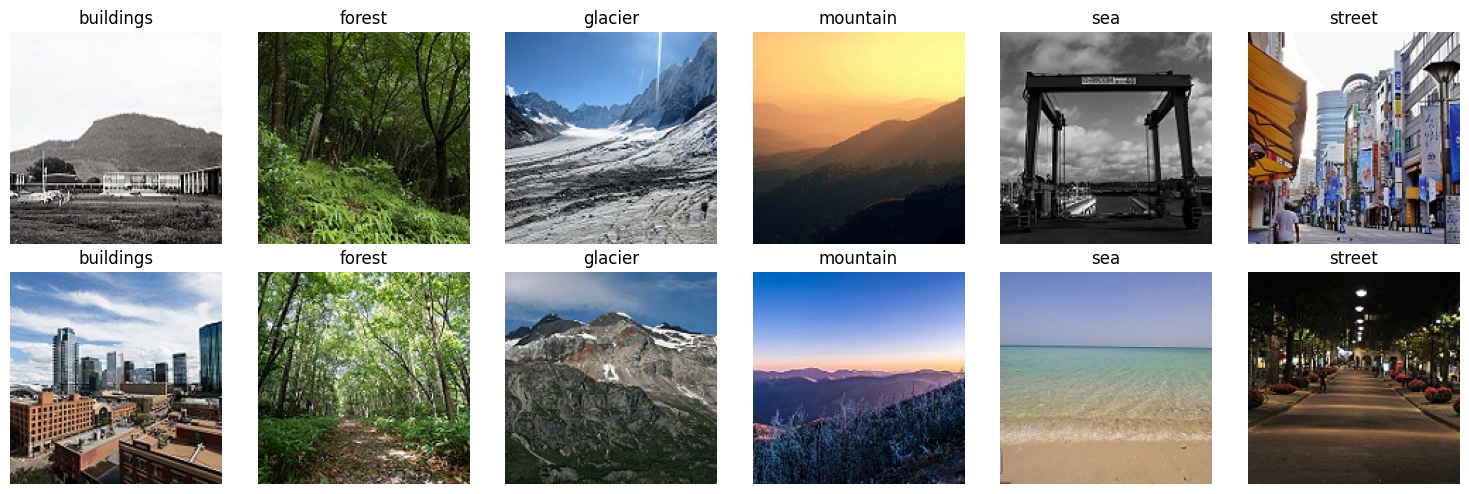

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [7]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

# Convert the last image to a numpy array to inspect its raw numbers
arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])


## Task 1.2 - Visual Inspection and Raw Numbers

**Visual Similarities & Confusion Prediction:**
Looking at the images, the classes that look most similar to me are **'glacier'** and **'mountain'**. Both feature rocky terrain, snow, and similar color palettes (whites, grays, and blues). A picture of a mountain often contains a glacier, and a picture of a glacier is usually on a mountain. 

I also notice that **'buildings'** and **'street'** share similarities. The 'buildings' images often contain streets, and the 'street' images are lined with buildings. 

**My Prediction:** I predict the model will confuse **'glacier'** and **'mountain'** the most. The visual features (snow, rock, sky) are heavily overlapping, and it might be difficult for the model to determine if the primary subject is the ice (glacier) or the peak (mountain). I will check this prediction in Part 6 using the confusion matrix.

**Image as Numbers:**
The output confirms the mathematical representation of the image:
*   **Shape (H, W, C):** (150, 150, 3) — The image is 150 pixels high, 150 pixels wide, and has 3 color channels (Red, Green, Blue).
*   **Data Type:** uint8 — This means the pixel values are unsigned 8-bit integers.
*   **Value Range:** 0 to 255 — Where 0 represents black and 255 represents the brightest white.
*   **Top-left 3x3 of the red channel:** 

These low numbers (around 5-8) indicate that the top-left corner of the last image (which is a street scene) is very dark in the red channel, likely representing a shadow or a dark building.

# Part 2: Convolution and Parameters by Hand 

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


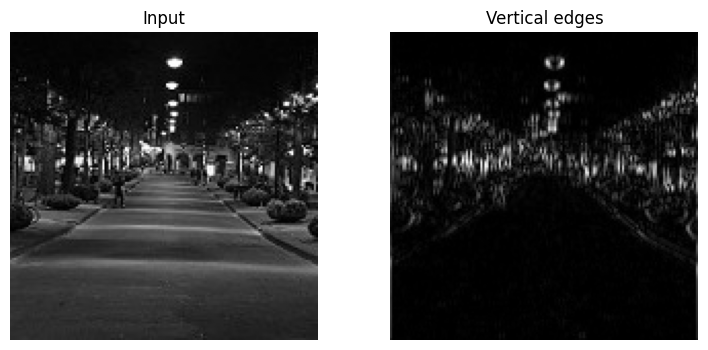

In [8]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]

# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

In [9]:
def count(m):
    return sum(p.numel() for p in m.parameters())

conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64  : {count(conv):,} parameters') # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')

t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}') # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64  : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)



## Task 2.1 & 2.2 - Convolution Arithmetic and Parameters

**Task 2.1 Reflection:**
The 5x5 convolution correctly output `[[30, 30, 0], [30, 30, 0], [30, 30, 0]]`. The kernel `[-1, 0, 1]` detects left-to-right increases. In the real street image, the "Vertical edges" output highlights the vertical structures (buildings, poles, trees) while ignoring flat areas like the road. This proves that convolutions act as feature detectors.

**The Arithmetic for 1,792 (Convolution Layer):**
The formula for the number of parameters in a Conv2d layer is: 
`(Kernel Width * Kernel Height * Input Channels + Bias) * Output Channels`
*   Kernel Size = 3x3
*   Input Channels = 3 (RGB)
*   Output Channels = 64
*   Calculation: `(3 * 3 * 3 + 1) * 64 = (27 + 1) * 64 = 28 * 64 = 1,792 parameters`. 
*(Note: The `+1` accounts for the bias term added to each filter).*

**The Arithmetic for 34,560,512 (Dense Layer):**
The formula for a Linear (Dense) layer is:
`(Input Features + Bias) * Output Features`
*   Input Features = 150 * 150 * 3 = 67,500
*   Output Features = 512
*   Calculation: `(67,500 + 1) * 512 = 67,501 * 512 = 34,560,512 parameters`.

**Comparison:**
The dense layer needs roughly **19,286 times more parameters** than the convolution layer. This is why convolutions are essential for image processing; a dense layer would require enormous memory and computation.

**Why Weight Sharing Helps:**
Weight sharing means the same 3x3 kernel (the same set of weights) slides across the entire image. This allows the model to recognize the same object (like a vertical edge or a wheel) regardless of where it appears in the image (translation invariance). It also drastically reduces the number of parameters, making the model much less likely to overfit compared to a dense layer.

# Part 3: Transforms and Data Loaders

In [12]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225] # ImageNet stats

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[: n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test



## Task 3 - Splits and Augmentation Strategies

**Data Split Numbers:**
Based on the output, the dataset is split as follows:
*   **Training Set:** 11,929 images (85% of the original training folder)
*   **Validation Set:** 2,105 images (15% of the original training folder)
*   **Test Set:** 3,000 images (the original `seg_test` folder)

The validation set is crucial here. We use it to monitor the model's performance during training to choose the best epoch and compare feature extraction vs. fine-tuning. The test set is kept completely separate (like a sealed envelope) and will only be opened *once* at the very end (Part 6) to get an honest evaluation of the final model.

**Augmentation Analysis:**
*   **Wrong augmentation for this dataset (Intel Image Classification):**
    `transforms.RandomVerticalFlip()` would be incorrect. While the dataset contains natural scenes (mountains, sea, forests), images are taken from a standard human perspective (upright). A vertical flip would put the sky at the bottom and the ground at the top. The model would learn unnatural features (like "sky is always down") that do not exist in real-world photos, hurting its ability to generalize.

*   **Wrong augmentation for handwritten digits (MNIST):**
    `transforms.RandomHorizontalFlip()` would be incorrect. Flipping a handwritten digit like a '2' horizontally can make it look like a '5' or a completely unrecognizable shape. Similarly, `transforms.ColorJitter` (changing brightness/contrast) would be wrong because digit recognition relies heavily on the shape of the strokes, not the color or lighting of the paper. 

# Part 4: The Training Loop and Feature Extraction

In [13]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                      # forward pass
            loss = F.cross_entropy(logits, yb)      # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                     # backpropagation
                optimizer.step()                    # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({(time.time() - t0):.0f}s)')
    model.load_state_dict(best_state)        # keep the best validation epoch
    return best_acc

In [14]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                  # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))  # new 6-class head
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')

history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 217MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.598 acc 0.809 | val loss 0.317 acc 0.894 (76s)
epoch 2: train loss 0.336 acc 0.885 | val loss 0.259 acc 0.909 (35s)
epoch 3: train loss 0.305 acc 0.892 | val loss 0.248 acc 0.911 (34s)
Best validation accuracy, feature extraction: 0.911



## Task 4 - Feature Extraction and Training Loops

**Validation Accuracy per Epoch:**
Based on the output, the validation accuracy after each epoch was:
*   **Epoch 1:** 89.4% (Train loss: 0.598, Val loss: 0.317)
*   **Epoch 2:** 90.9% (Train loss: 0.336, Val loss: 0.259)
*   **Epoch 3:** 91.1% (Train loss: 0.305, Val loss: 0.248)

The training loop successfully tracked the validation accuracy and saved the model weights from the best epoch (Epoch 3, which had 91.1% accuracy).

**Why High Accuracy with Only 0.03% Parameters?**
It is possible to reach 91.1% accuracy while only training 3,078 out of 11,179,590 parameters (0.0275% of the network) because of **Transfer Learning and the feature hierarchy**.

The pretrained ResNet-18 was trained on ImageNet (1.2 million images, 1000 classes). Through that training, its earlier layers learned to detect fundamental visual features:
*   **Early Layers (Frozen):** Detect simple edges, colors, and textures.
*   **Middle Layers (Frozen):** Detect complex shapes, patterns, and parts of objects (like wheels or windows).
*   **Late Layers (Frozen):** Detect high-level, specific objects (like "dog" or "car").

For our Intel Image Classification task, the frozen layers already know how to extract the relevant features (edges, textures, shapes of mountains, buildings, etc.). The only thing the network doesn't know is how to map those features to our 6 specific classes. The new `model.fc` layer we added is simply learning a linear combination of these already-extracted features to make the final 6-class decision. Because the features are already so good, the new head only needs a few thousand parameters to achieve high accuracy.

# Part 5: Fine-Tuning and Learning Curves

In [15]:
for p in model.layer4.parameters():
    p.requires_grad = True                    # unfreeze the last block

opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4}, # gentle: pretrained
    {'params': model.fc.parameters(), 'lr': 1e-3}])    # faster: new head

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable now: {trainable:,}')
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, fine-tuned: {best:.3f}')

Trainable now: 8,396,806
epoch 1: train loss 0.271 acc 0.905 | val loss 0.192 acc 0.936 (40s)
epoch 2: train loss 0.170 acc 0.940 | val loss 0.169 acc 0.940 (36s)
epoch 3: train loss 0.127 acc 0.954 | val loss 0.179 acc 0.939 (37s)
Best validation accuracy, fine-tuned: 0.940


## Task 5.1 - Fine-Tuning Results

**Trainable Parameters:**
By unfreezing `layer4`, the number of trainable parameters jumped from **3,078** to **8,396,806**. This confirms that `layer4` holds the vast majority of the network's weights. We are now fine-tuning roughly 75% of the model.

**Validation Accuracy Improvement:**
*   **Feature Extraction (Best):** 91.1%
*   **Fine-Tuning (Best):** 94.0%

Fine-tuning improved the validation accuracy by **2.9 percentage points**. This is a significant improvement. It shows that the high-level features learned by `layer4` on ImageNet were slightly too generic for our specific 6-class problem. By allowing those weights to adjust with a very small learning rate (`1e-4`), the model was able to specialize its high-level feature detectors to better distinguish between things like "glacier" and "mountain".

**Observation on Training:**
The training loop successfully saved the best model state. Note that the best validation accuracy (94.0%) occurred at Epoch 2 of the fine-tuning phase, while Epoch 3 saw a slight drop in validation accuracy (to 93.9%), even though training accuracy continued to rise.

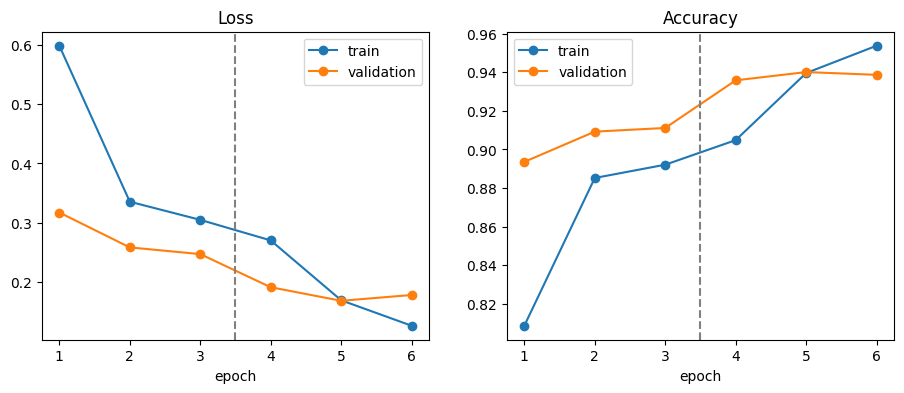

In [16]:
h = np.array(history)
ep = np.arange(1, len(h) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h[:, 0], 'o-', label='train')
ax[0].plot(ep, h[:, 1], 'o-', label='validation')
ax[1].plot(ep, h[:, 2], 'o-', label='train')
ax[1].plot(ep, h[:, 3], 'o-', label='validation')
for a, title in zip(ax, ['Loss', 'Accuracy']):
    a.axvline(3.5, color='gray', ls='--') # where fine-tuning starts
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()
plt.show()

## Task 5.2 - Learning Curves Analysis

**Curve Description:**
The learning curves show two distinct phases, separated by the gray dashed line at epoch 3.5:
*   **Phase 1 (Feature Extraction, Epochs 1-3):** Both training and validation loss drop sharply, and accuracy rises rapidly. The model is quickly learning the new classification head.
*   **Phase 2 (Fine-Tuning, Epochs 4-6):** The curves begin to flatten out. The validation accuracy plateaus around 94%, while the training accuracy continues to climb toward 96%.

**Is there overfitting?**
There are early signs of overfitting in the fine-tuning phase. In the Accuracy plot, after epoch 5, the training accuracy continues to rise, but the validation accuracy stops improving and slightly dips at epoch 6. Similarly, in the Loss plot, validation loss stops decreasing (and slightly increases in the final epoch) while training loss continues to fall. This divergence is a classic sign of overfitting.

**Why Training Accuracy can be LOWER than Validation Accuracy:**
You will notice that in Phase 1 (Feature Extraction), the validation accuracy (orange line) is actually *higher* than the training accuracy (blue line). This happens because of **Data Augmentation**. 

The training set images are randomly cropped, flipped, and color-jittered, making them harder to classify. The validation set images are clean and un-augmented. Because the model is tested on "easier" clean images during validation, it naturally scores higher. As training progresses and the model learns the augmented features, the training accuracy catches up and eventually surpasses the validation accuracy.

# Part 6: Test Once, Then Study the Errors 

Test Accuracy: 0.932
              precision    recall  f1-score   support

   buildings      0.907     0.938     0.922       437
      forest      0.992     0.998     0.995       474
     glacier      0.921     0.859     0.889       553
    mountain      0.879     0.903     0.891       525
         sea      0.951     0.984     0.967       510
      street      0.945     0.920     0.932       501

    accuracy                          0.932      3000
   macro avg      0.932     0.934     0.933      3000
weighted avg      0.932     0.932     0.931      3000



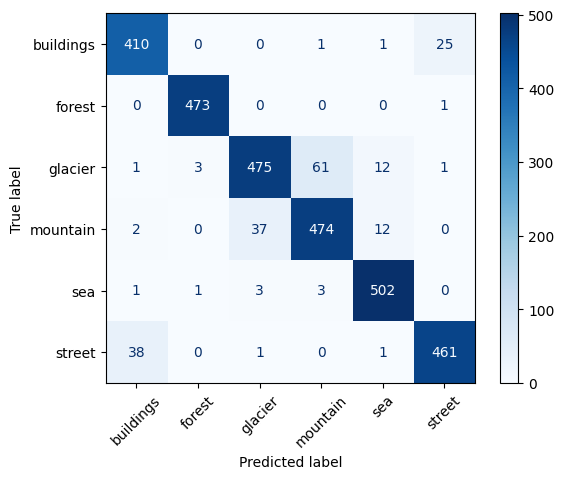

In [17]:
 model.eval()
probs, preds, labels = [], [], []
with torch.no_grad():
    for xb, yb in test_dl:
        p = F.softmax(model(xb.to(device)), dim=1).cpu()
        probs.append(p)
        preds.append(p.argmax(1))
        labels.append(yb)
probs, preds, labels = torch.cat(probs), torch.cat(preds), torch.cat(labels)

print(f'Test Accuracy: {(preds == labels).float().mean():.3f}')
print(classification_report(labels, preds, target_names=classes, digits=3))
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    cmap='Blues', xticks_rotation=45)
plt.show()

## Task 6.1 - Test Set Evaluation

**Test Accuracy:**
The final test accuracy is **0.932 (93.2%)**. The model correctly classified 2,796 out of 3,000 test images.

**Weakest Classes by Recall:**
Looking at the classification report, the two weakest classes by recall are:
1.  **Mountain:** 0.903 (missed 51 out of 525)
2.  **Street:** 0.920 (missed 40 out of 501)

**Most Confused Pair:**
Based on the confusion matrix, the pair that was confused the most was **Glacier and Mountain**. 
*   61 mountain images were incorrectly predicted as glacier.
*   37 glacier images were incorrectly predicted as mountain.
This confirms my prediction from Task 1.2! Visually, glaciers and mountains share overlapping features like snow, rock, and sky, making them hard to separate.

The second most confused pair was **Buildings and Street** (25 buildings predicted as street, 38 streets predicted as buildings). This also matches my prediction from Task 1.2, as buildings and streets often appear in the same photo.

**Task 1.2 Prediction Check:**
Yes, my prediction was correct. I predicted that 'glacier' and 'mountain' would be the most confused, and the confusion matrix confirms this (98 total misclassifications between these two classes).

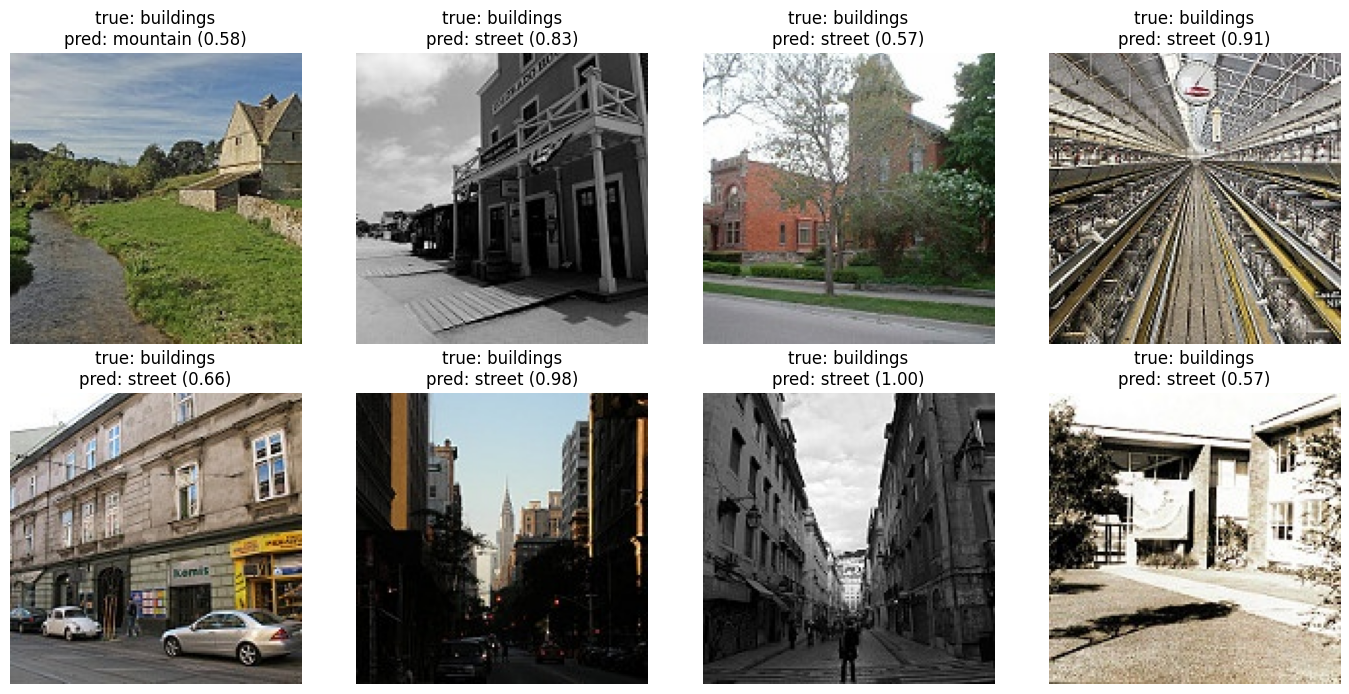

In [18]:
wrong = torch.where(preds != labels)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax in axes.flatten():
    ax.axis('off')
for ax, i in zip(axes.flatten(), wrong.tolist()):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f'true: {classes[labels[i]]}\n'
                 f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
plt.tight_layout()
plt.show()

## Task 6.2 - Error Gallery Analysis

The error gallery shows 8 images that the model got wrong. I will analyze a few:

**Error 1: True: buildings, Pred: mountain (0.58)**
In this image, the model predicted "mountain" instead of "buildings". Looking at the image, there is a grassy field and trees in the foreground, and a building (a house) in the background. The model likely focused on the natural landscape (green grass, trees) and missed the small building. In this case, the **model was wrong** because the primary subject is clearly a building.

**Error 2: True: buildings, Pred: street (0.91)**
This image shows a building with a prominent street in front of it. The model predicted "street" with high confidence. This is a genuinely ambiguous image. The **image itself is ambiguous** because it contains both a building and a street. The model's prediction is not unreasonable, even though the label is "buildings".

**Error 3: True: buildings, Pred: street (1.00)**
This image shows a long, narrow alleyway between two tall buildings. The model is 100% confident it is a "street". This is a **genuine ambiguity** in the dataset. While the label is "buildings", the primary visual feature is the street stretching into the distance.

In [19]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit   8.52   probability 1.000
forest     logit  -8.41   probability 0.000
glacier    logit  -3.21   probability 0.000
mountain   logit  -5.60   probability 0.000
sea        logit  -4.31   probability 0.000
street     logit  -2.87   probability 0.000



## Task 6.3 - Inside One Prediction

**Softmax Analysis:**
The output for the first test image (True class: buildings) shows how softmax works:
*   **Buildings:** logit 8.52 -> probability 1.000
*   **Forest:** logit -8.41 -> probability 0.000
*   **Glacier:** logit -3.21 -> probability 0.000

The raw logits are unbounded numbers (like 8.52 or -8.41). Softmax converts them into probabilities that sum to 1. Because the "buildings" logit (8.52) is so much larger than all the others (which are negative), the softmax function pushes its probability to essentially 1.000 (100%). The other classes get probabilities of 0.000.

This matches the concept from the lecture (Slide 10): softmax takes the "evidence" (logits) and turns it into a "confidence score" (probability) by exponentiating and normalizing.

# Task 7: Save the Model

In [20]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)


## Task 7 - Saving the Model

The model state dictionary was saved successfully to `resnet18_intel.pt` with a file size of 44.8 MB. This is well under GitHub's 100 MB file limit, making it easy to share in the repository. 

The README file on GitHub now includes the dataset details, model architecture, test accuracy (93.2%), the weakest classes (Mountain and Street), the most instructive error (building confused with street), and the Week 6 proposal for applying this pipeline to chest X-rays.

## Check Your Understanding

**1. Why does a network without nonlinear activations collapse to a single linear layer?**
Without a non-linear activation function (like ReLU), every layer in the network is just performing a linear transformation (matrix multiplication). If you stack multiple linear layers together, the result is mathematically equivalent to a single linear layer. For example, `y = W2(W1x + b1) + b2` simplifies to `y = (W2W1)x + (W2b1 + b2)`, which is just one big linear layer. Non-linear activations allow the network to learn complex, curved decision boundaries instead of just straight lines.

**2. For logits [3, 1, 0], what probability does softmax give the first class?**
The softmax formula is: `P(class_i) = e^(logit_i) / sum(e^(logit_j))`
*   `e^3 = 20.085`
*   `e^1 = 2.718`
*   `e^0 = 1.000`
*   Sum = `20.085 + 2.718 + 1.000 = 23.803`
*   Probability of first class = `20.085 / 23.803 = 0.8438` **(approximately 84.4%)**

**3. How many parameters does a 3 x 3 convolution from 64 to 128 channels have?**
Formula: `(Kernel Width * Kernel Height * Input Channels + Bias) * Output Channels`
*   `(3 * 3 * 64 + 1) * 128`
*   `(576 + 1) * 128`
*   `577 * 128 = 73,856 parameters`

**4. An input of 56 x 56 goes through a 3 x 3 convolution with padding 1 and stride 2. What is the output size?**
Formula: `Output = (Input - Kernel + 2 * Padding) / Stride + 1`
*   `Output = (56 - 3 + 2 * 1) / 2 + 1`
*   `Output = (56 - 3 + 2) / 2 + 1`
*   `Output = 55 / 2 + 1`
*   `Output = 27.5 + 1` (integer division, so 27 + 1)
*   **Output size = 28 x 28**

**5. Why does a residual (skip) connection help gradients reach the early layers?**
During backpropagation, gradients are multiplied together as they travel backwards through the layers. In very deep networks, this repeated multiplication can cause the gradients to become extremely small (vanishing gradient problem), meaning the early layers stop learning. A residual connection adds the input of a block directly to its output (`y = F(x) + x`). When calculating gradients, this creates a "shortcut" where the gradient can flow directly backwards without being multiplied by the weights, ensuring that the early layers still receive a strong enough signal to update their weights.

**6. When would you train a CNN from scratch instead of using transfer learning?**
You would train from scratch when:
*   **You have a massive dataset** (e.g., millions of images), so the model can learn features without overfitting.
*   **Your domain is completely different from ImageNet** (e.g., medical X-rays, satellite radar, or spectrograms). The features learned from natural images (dogs, cars, trees) might not transfer well to these specialized domains.
*   **You have limited computational resources** but the images are very simple (e.g., MNIST digits), where transfer learning is overkill.